# Złożony proces Poissona 

### Zadanie 2. metoda przerzedzania

In [30]:
import numpy as np 
import matplotlib.pyplot as plt 
from lista_4_funkcje import plot_poisson, get_poisson_value
import scipy
import math

[ 0.54872986  2.43408778 10.7960087  54.58291954]


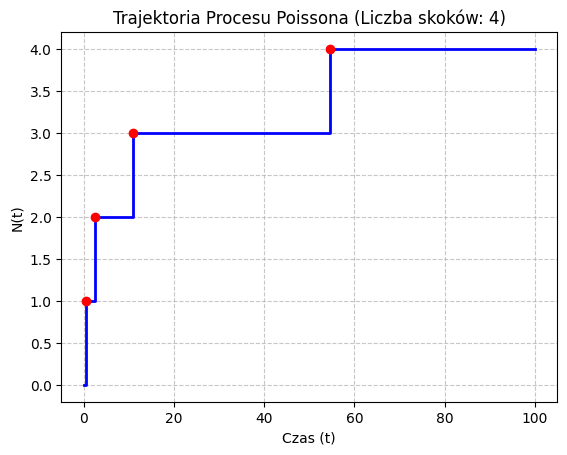

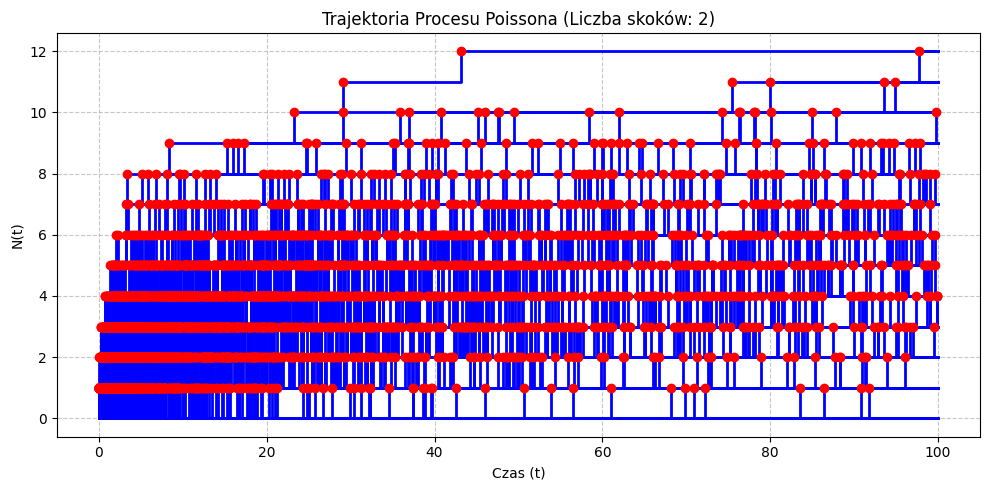

In [31]:
# PRZYKŁADOWA FUNKCJA 1/(t+1) = lambda; M = 1 

def example_func(x):
    return np.power(x+1,-1)

def NHPP_thining(M, T, func):
    """M >= max(func) otherwise it wont work """
    I=0
    S = []
    t = - 1/M * np.log(np.random.uniform())
    while t <=T:
        if np.random.uniform() <= func(t)/M:
            I += 1 
            S.append(t)
        t += - 1/M * np.log(np.random.uniform())
    return np.array(S) 

def numeric_integrate(func, t):
    integral,_ = scipy.integrate.quad(func,0,t)
    return integral 

M = 1
T=100

a = NHPP_thining(M, T, example_func)
print(a)
plot_poisson(a, T)

# TRAJEKTOIE NA JEDNYM WYKRESIE
plt.figure(figsize=(10, 5))
for i in range(1000):
    a = NHPP_thining(M, T, example_func)
    plot_poisson(a, T)
plt.tight_layout()
plt.show()


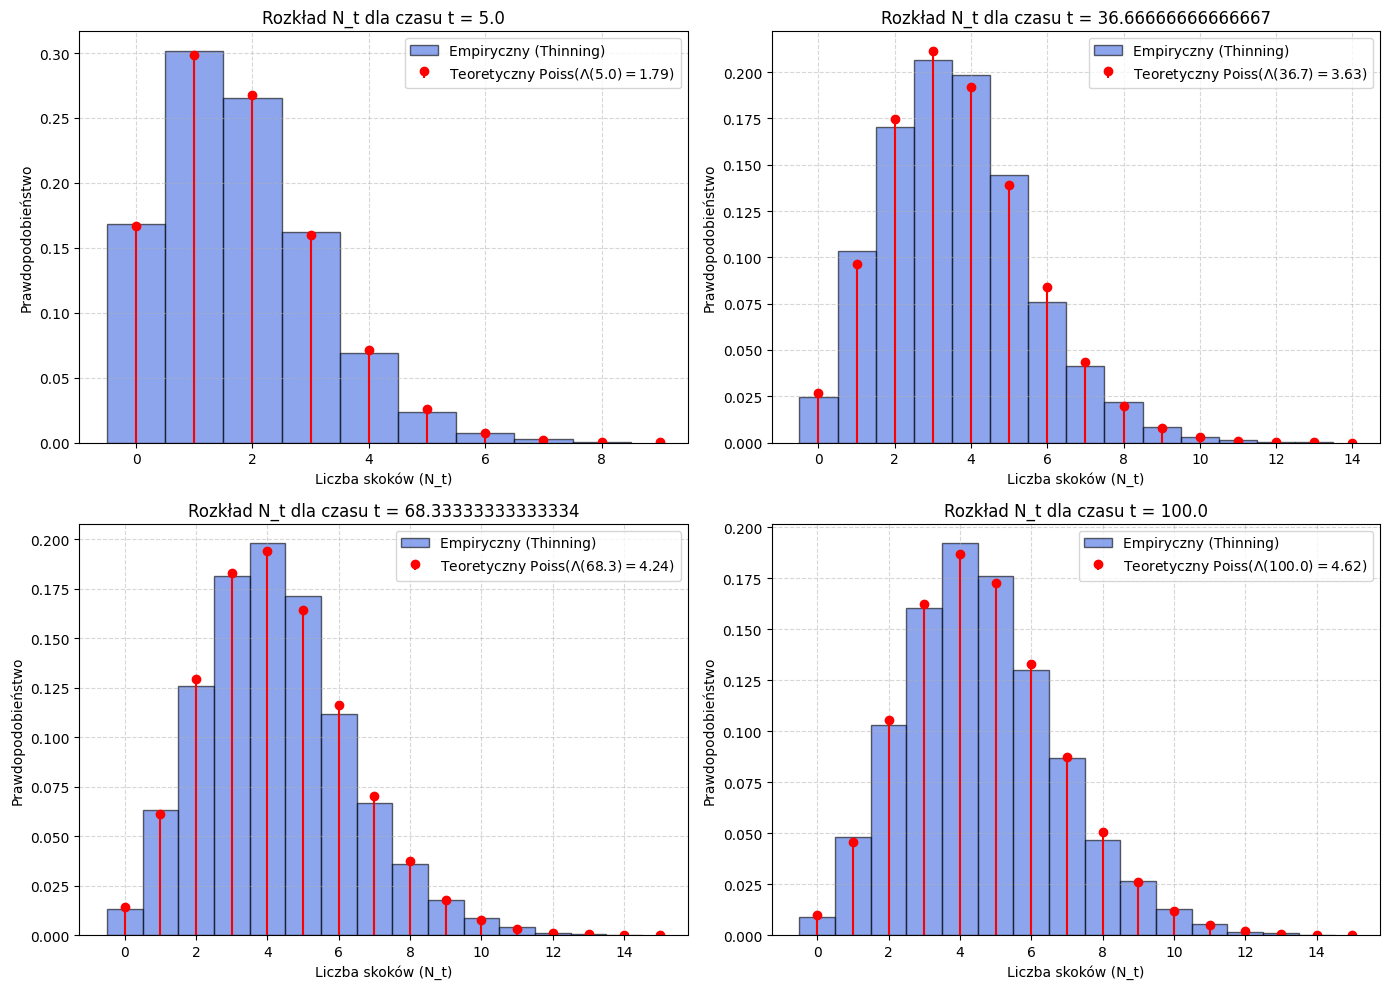

In [32]:
# SIMULATION 
M = 1
T=100
num_simulation =6000

test_times = np.linspace(5,T,4)
empirical_counts = {t: [] for t in test_times}

for i in range(num_simulation):

    jumps = NHPP_thining(M, T, example_func)
    for t in test_times:
        counts = np.sum(jumps < t)
        empirical_counts[t].append(counts)


plt.figure(figsize=(14, 10))
for i, t in enumerate(test_times, 1):
    expected_lambda = numeric_integrate(example_func, t)

    simulated_data = empirical_counts[t]
    max_jumps = max(simulated_data) +2

    k_values = np.arange(0,max_jumps)
    theoretical_poisson = (np.power(expected_lambda, k_values)* np.exp(-expected_lambda)) / np.array([math.factorial(k) for k in k_values])

    plt.subplot(len(test_times)//2, len(test_times)//2, i)

    plt.hist(simulated_data, bins=np.arange(max_jumps)-0.5, density=True, 
             alpha=0.6, color='royalblue', edgecolor='black', label='Empiryczny (Thinning)')

    plt.stem(k_values, theoretical_poisson, linefmt='r-', markerfmt='ro', 
             basefmt=' ', label=f'Teoretyczny Poiss($\\Lambda({t:.1f})={expected_lambda:.2f}$)')

    plt.title(f"Rozkład N_t dla czasu t = {t}")
    plt.xlabel("Liczba skoków (N_t)")
    plt.ylabel("Prawdopodobieństwo")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Zadanie 3. 
Metoda odwrotnej dystrybuanty 

In [33]:
# inverse of example_func
def inverse_lambda(x):
    return np.log(x+1)

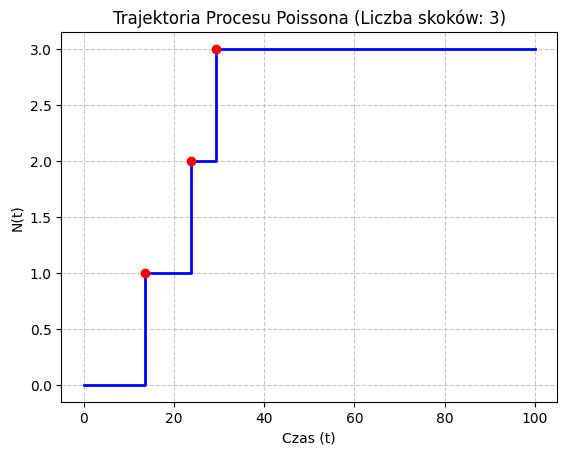

In [34]:
# SPOSÓB 2. 

def NHPP_inverse(func, T):
    """func - integral of lambda(t), S = inversed func(t)/func(T), t is argument"""
    N_T = np.random.poisson(func(T))
    S = np.power(np.e, np.random.uniform(size=N_T) * np.log(T+1)) -1
    return sorted(S)

test = NHPP_inverse(lambda x: np.log(x+1), T)

plot_poisson(test, T)

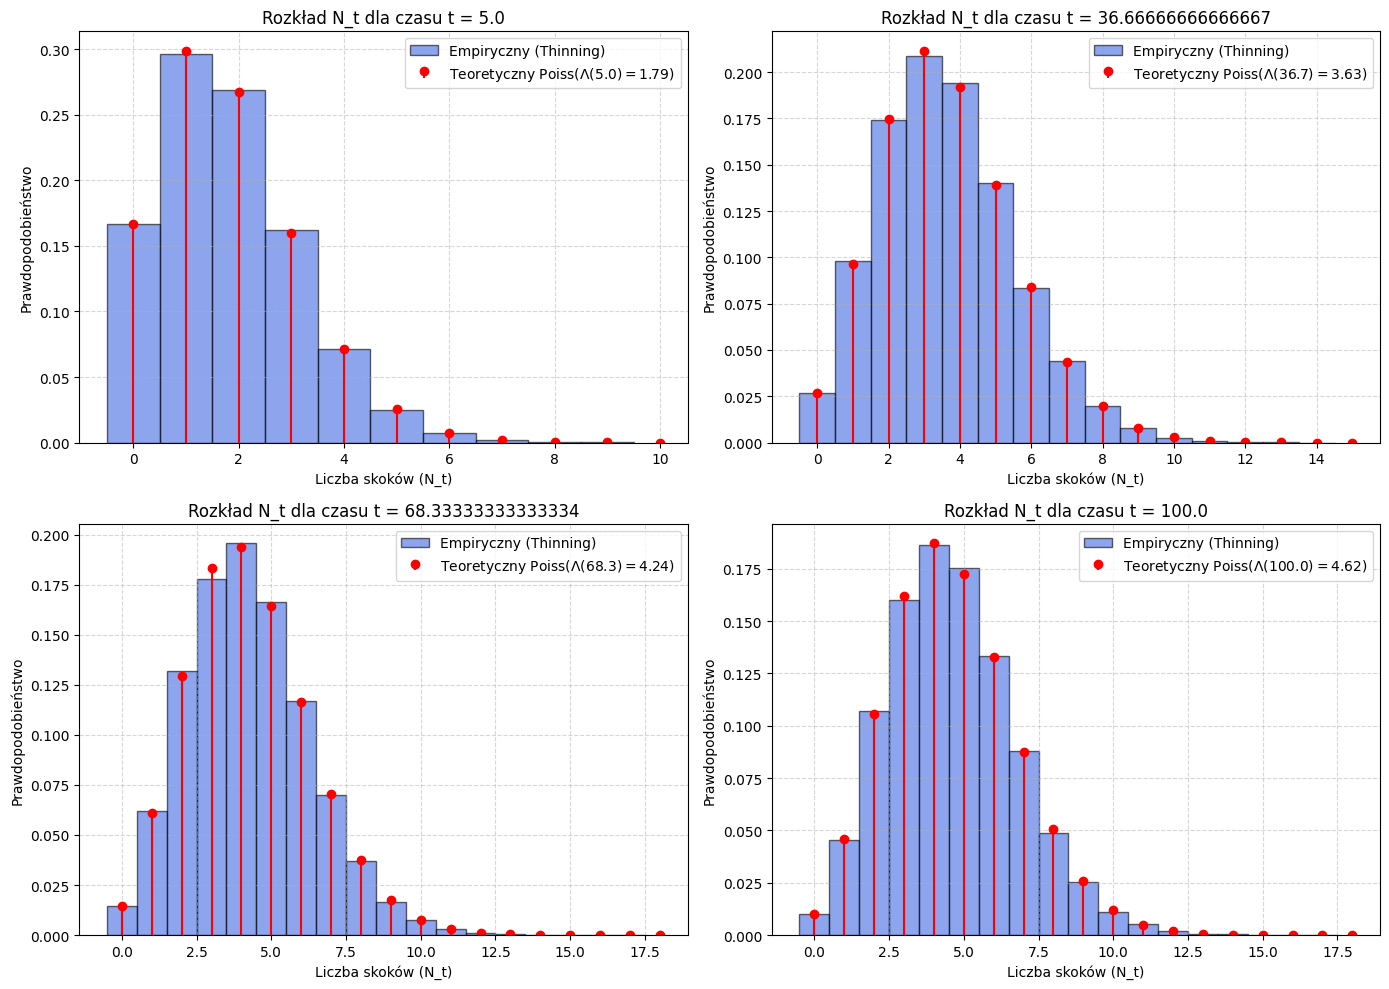

In [35]:
# SIMULATION 
T=100
num_simulation =60000
test_times = np.linspace(5,T,4)

empirical_counts = {t: [] for t in test_times}

for i in range(num_simulation):

    jumps = NHPP_inverse(inverse_lambda, T)
    for t in test_times:
        counts = np.sum(jumps < t)
        empirical_counts[t].append(counts)


plt.figure(figsize=(14, 10))
for i, t in enumerate(test_times, 1):
    expected_lambda = numeric_integrate(example_func, t)

    simulated_data = empirical_counts[t]
    max_jumps = max(simulated_data) +2

    k_values = np.arange(0,max_jumps)
    theoretical_poisson = (np.power(expected_lambda, k_values)* np.exp(-expected_lambda)) / np.array([math.factorial(k) for k in k_values])

    plt.subplot(len(test_times)//2, len(test_times)//2, i)

    plt.hist(simulated_data, bins=np.arange(max_jumps)-0.5, density=True, 
             alpha=0.6, color='royalblue', edgecolor='black', label='Empiryczny (Thinning)')

    plt.stem(k_values, theoretical_poisson, linefmt='r-', markerfmt='ro', 
             basefmt=' ', label=f'Teoretyczny Poiss($\\Lambda({t:.1f})={expected_lambda:.2f}$)')

    plt.title(f"Rozkład N_t dla czasu t = {t}")
    plt.xlabel("Liczba skoków (N_t)")
    plt.ylabel("Prawdopodobieństwo")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Zadanie 4. 
Suma dwóch procesów poissona 

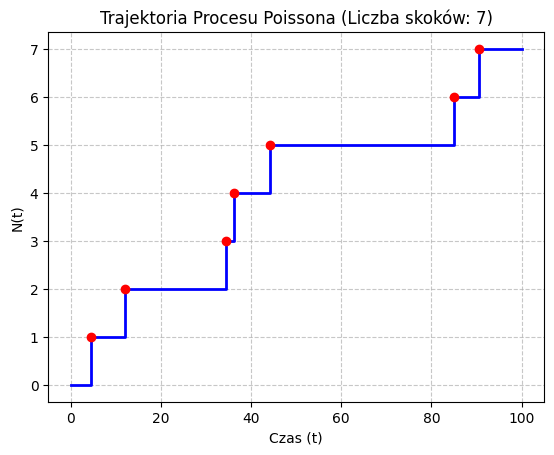

In [36]:
def example_func_1(x):
    return np.sqrt(x)/100

def example_func_2(x):
    return np.power(x+1, -1)

def merged_func(x):
    return np.power(x+1, -1) + np.sqrt(x)/100

T =100

M_1 = np.sqrt(100)/100
S_1 = NHPP_thining(M_1, T, example_func_1)

M_2 = 1
S_2 = NHPP_thining(M_2, T, example_func_2)

merged_NHPP = np.sort(np.concatenate((S_2,S_1)))
plot_poisson(merged_NHPP, T)
#plot_poisson(S_2, T)
#plot_poisson(S_1,T)

Sprawdzenie czy rzeczywiście
$\lambda_{1}(t) + \lambda_{2}(t) = \lambda_{new}(t)$ 

Porównamy rozkłady liczby skoków dla róznych t, podobnie jak w zadaniach wyżej. 

Tworzymy dwie oddzielne symulacje i łaczymy ze sobą listy czasów skoków. 

tworzymy histogram dla liczby skoków dla różnych czasów t i porównujemy z histogramem teoretycznym funkcji, która jest sumą intensywności obu procesów. 

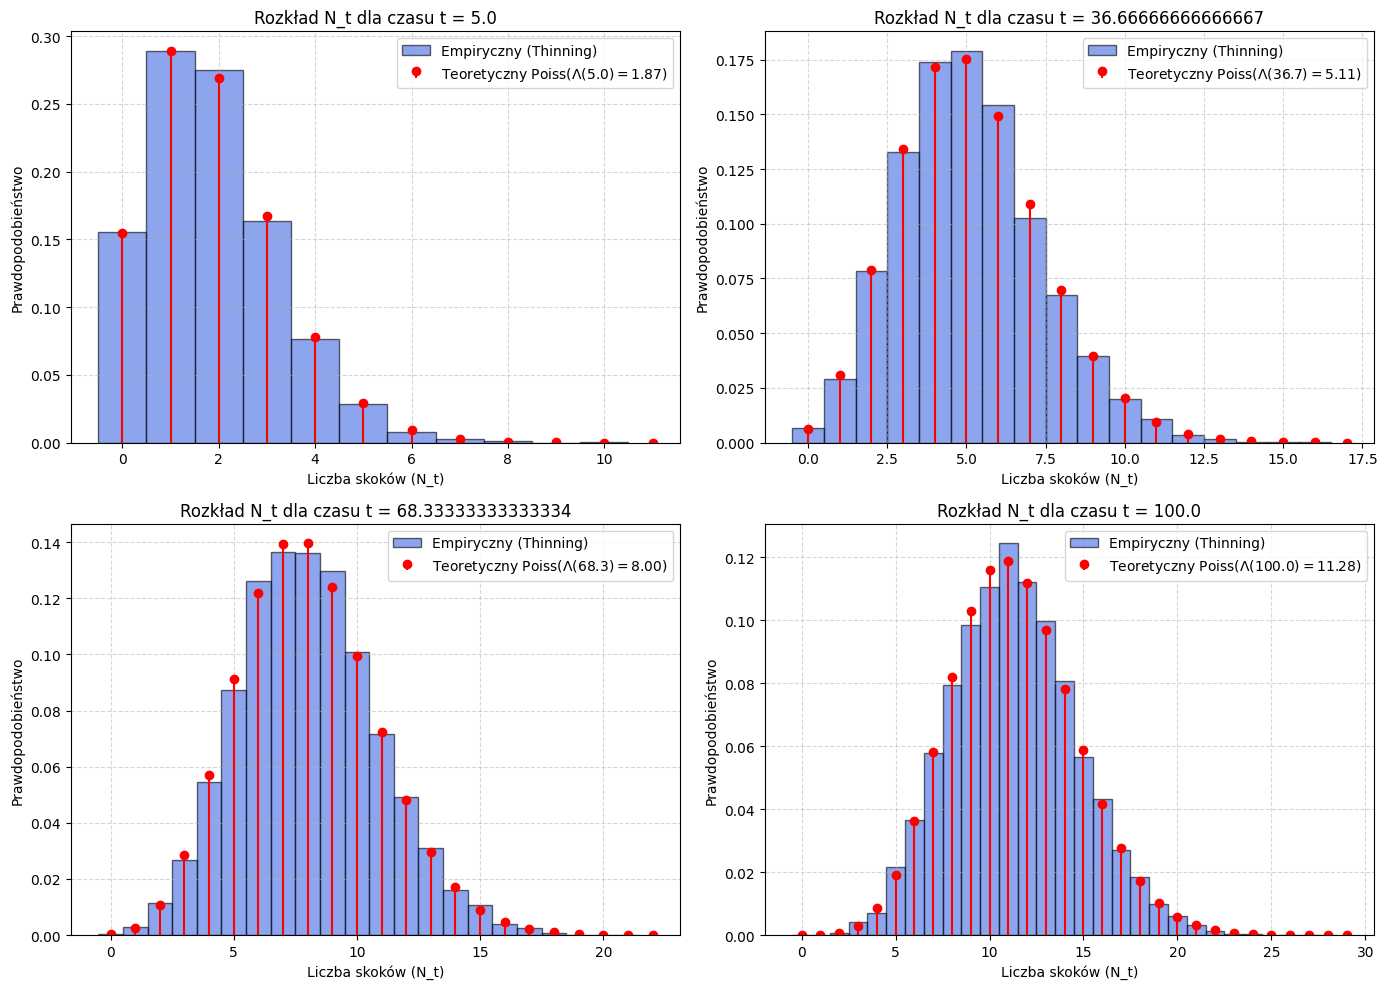

In [37]:
# SIMULATION 
M_1 = 0.1
M_2 = 1
T=100
num_simulation =10000

test_times = np.linspace(5,T,4)
empirical_counts = {t: [] for t in test_times}

for i in range(num_simulation):

    jumps_1 = NHPP_thining(M_1, T, example_func_1)
    jumps_2 = NHPP_thining(M_2, T, example_func_2)
    jumps = np.concatenate((jumps_1,jumps_2))

    for t in test_times:
        counts = np.sum(jumps < t)
        empirical_counts[t].append(counts)


plt.figure(figsize=(14, 10))
for i, t in enumerate(test_times, 1):
    expected_lambda = numeric_integrate(merged_func, t)

    simulated_data = empirical_counts[t]
    max_jumps = max(simulated_data) +2

    k_values = np.arange(0,max_jumps)
    theoretical_poisson = (np.power(expected_lambda, k_values)* np.exp(-expected_lambda)) / np.array([math.factorial(k) for k in k_values])

    plt.subplot(len(test_times)//2, len(test_times)//2, i)

    plt.hist(simulated_data, bins=np.arange(max_jumps)-0.5, density=True, 
             alpha=0.6, color='royalblue', edgecolor='black', label='Empiryczny (Thinning)')

    plt.stem(k_values, theoretical_poisson, linefmt='r-', markerfmt='ro', 
             basefmt=' ', label=f'Teoretyczny Poiss($\\Lambda({t:.1f})={expected_lambda:.2f}$)')

    plt.title(f"Rozkład N_t dla czasu t = {t}")
    plt.xlabel("Liczba skoków (N_t)")
    plt.ylabel("Prawdopodobieństwo")
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Zadanie 5. 
Funkcja charakterystyczna empiryczna


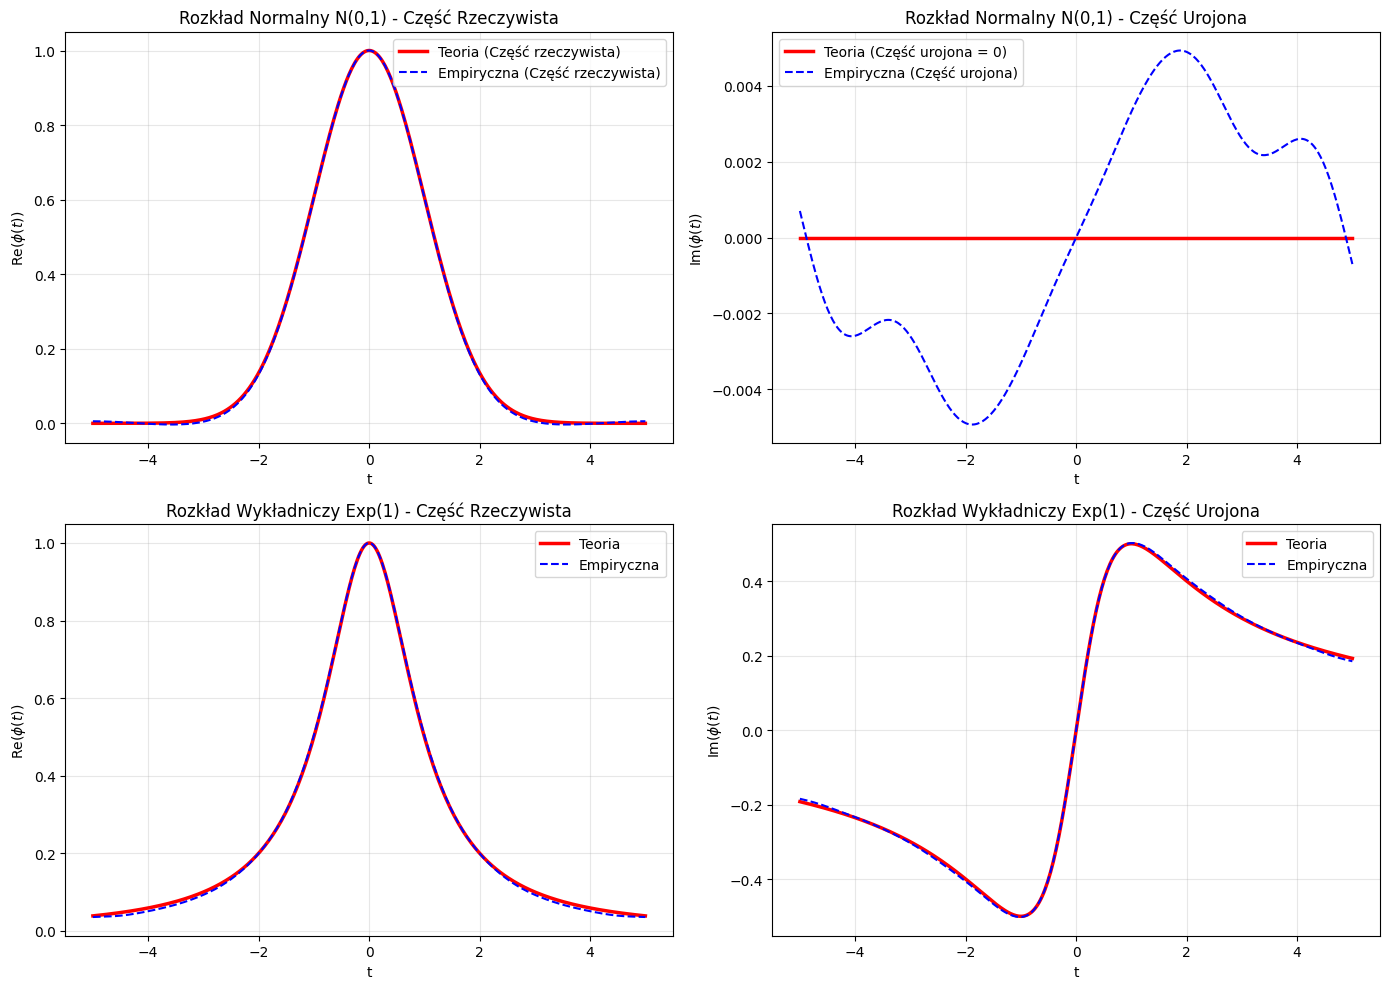

In [38]:
def empirical_cf(t_vec, data):
    """
    t_vec: vector of t points 
    data: one dimensional random sample (X_1, ..., X_n)
    """

    matrix = t_vec[:, None] * data
    
    # mean for each row
    ecf = np.mean(np.exp(1j * matrix), axis=1)
    return ecf


def theoretical_cf_normal(t_vec):
    return np.exp(-0.5 * t_vec**2)

def theoretical_cf_exponential(t_vec, lam=1.0):
    return lam / (lam - 1j * t_vec)

# params
n_samples = 50000
t_vals = np.linspace(-5, 5, 400)


normal_data = np.random.normal(0, 1, n_samples)
exp_data = np.random.exponential(scale=1.0, size=n_samples) # scale = 1/lambda, dla 1.0 lambda=1


ecf_normal = empirical_cf(t_vals, normal_data)
tcf_normal = theoretical_cf_normal(t_vals)

ecf_exp = empirical_cf(t_vals, exp_data)
tcf_exp = theoretical_cf_exponential(t_vals, lam=1.0)

# vizualization
plt.figure(figsize=(14, 10))

# Normal
plt.subplot(2, 2, 1)
plt.plot(t_vals, tcf_normal, 'r-', linewidth=2.5, label='Teoria (Część rzeczywista)')
plt.plot(t_vals, np.real(ecf_normal), 'b--', label='Empiryczna (Część rzeczywista)')
plt.title("Rozkład Normalny N(0,1) - Część Rzeczywista")
plt.xlabel("t")
plt.ylabel(r"$\operatorname{Re}(\phi(t))$")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 2)
# Teoretical distribution doesnt have imaginary part
plt.plot(t_vals, np.zeros_like(t_vals), 'r-', linewidth=2.5, label='Teoria (Część urojona = 0)')
plt.plot(t_vals, np.imag(ecf_normal), 'b--', label='Empiryczna (Część urojona)')
plt.title("Rozkład Normalny N(0,1) - Część Urojona")
plt.xlabel("t")
plt.ylabel(r"$\operatorname{Im}(\phi(t))$")
plt.legend()
plt.grid(True, alpha=0.3)

# Exp(1)
plt.subplot(2, 2, 3)
plt.plot(t_vals, np.real(tcf_exp), 'r-', linewidth=2.5, label='Teoria')
plt.plot(t_vals, np.real(ecf_exp), 'b--', label='Empiryczna')
plt.title("Rozkład Wykładniczy Exp(1) - Część Rzeczywista")
plt.xlabel("t")
plt.ylabel(r"$\operatorname{Re}(\phi(t))$")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 2, 4)
plt.plot(t_vals, np.imag(tcf_exp), 'r-', linewidth=2.5, label='Teoria')
plt.plot(t_vals, np.imag(ecf_exp), 'b--', label='Empiryczna')
plt.title("Rozkład Wykładniczy Exp(1) - Część Urojona")
plt.xlabel("t")
plt.ylabel(r"$\operatorname{Im}(\phi(t))$")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Zadanie 6. 
Złożony proces poissona - Analiza rozkładów skoków

[ 5.26792021  5.54497018  8.42397467 22.90395516] [-0.6783625  -0.52339384 -0.39033823 -0.02090651]
[-0.6783625  -0.52339384 -0.39033823 -0.02090651]


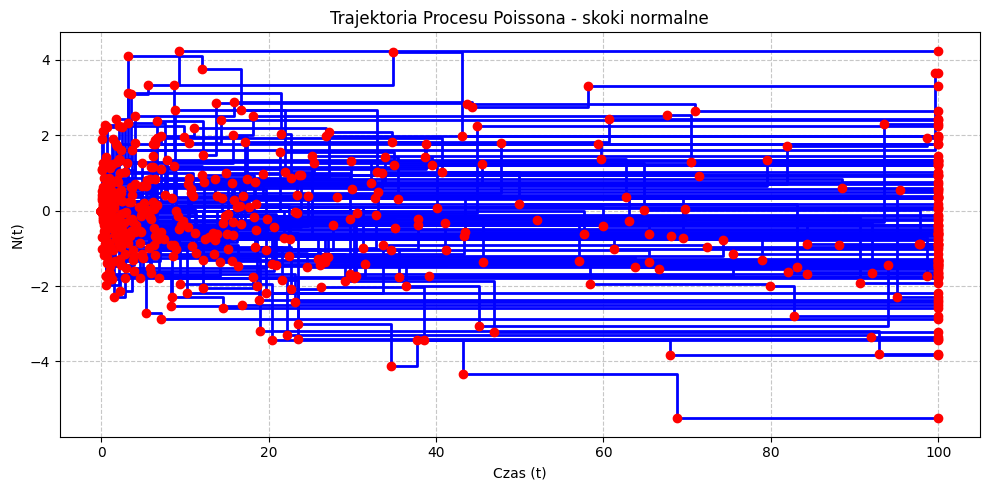

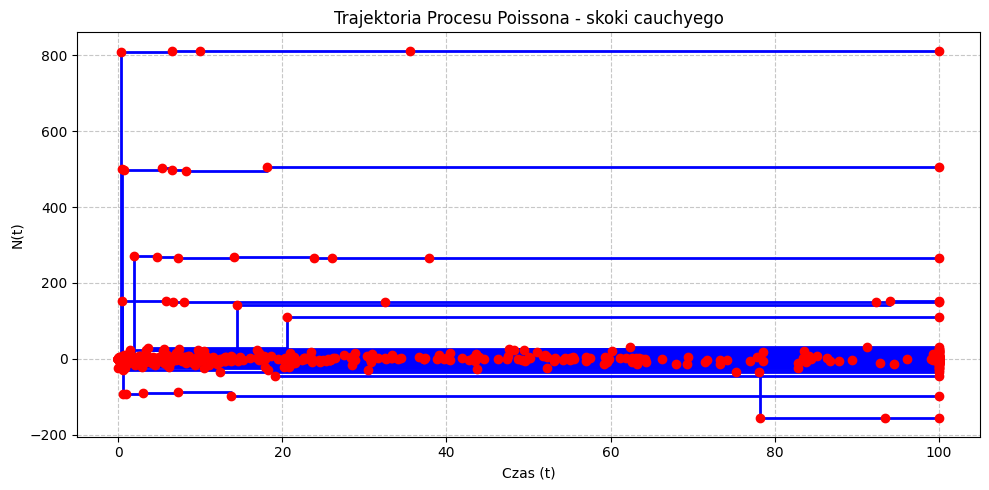

In [81]:
def plot_compound_poisson(S,J, T, label_jumps=None, label_trajectory=None):
    if len(J) == 0:
        x = np.array([0, T])
        y = np.array([0, 0])
    else:
        x = np.concatenate(([0], S, [T]))
        y = np.concatenate(([0], J, [J[-1]]))

    
    # 'where=post' - CADLAG
    plt.step(x, y, where='post', label=label_jumps, color='blue', linewidth=2)
    
    # points in jump places
    plt.scatter(x, y, color='red', zorder=3, label=label_trajectory)


def NHPP_thining_normal(M, T, func, mean=0, std=1):
    """M >= max(func) otherwise it wont work """
    I=0
    S = []
    t = - 1/M * np.log(np.random.uniform())
    while t <=T:
        if np.random.uniform() <= func(t)/M:
            I += 1 
            S.append(t)
        t += - 1/M * np.log(np.random.uniform())
    jumps = np.cumsum(np.random.normal(loc=mean, scale=std, size=len(S)))
    return np.array(S), jumps

def NHPP_thining_cauchy(M, T, func):
    I=0
    S = []
    t = - 1/M * np.log(np.random.uniform())
    while t <=T:
        if np.random.uniform() <= func(t)/M:
            I += 1 
            S.append(t)
        t += - 1/M * np.log(np.random.uniform())
    jumps = np.cumsum(np.random.standard_cauchy(size=len(S)))
    return np.array(S), jumps

def NHPP_thining_expon(M, T, func, lamb=1):
    I=0
    S = []
    t = - 1/M * np.log(np.random.uniform())
    while t <=T:
        if np.random.uniform() <= func(t)/M:
            I += 1 
            S.append(t)
        t += - 1/M * np.log(np.random.uniform())
    jumps = np.cumsum(np.random.exponential(scale=1/lamb, size=len(S)))
    return np.array(S), jumps

S, J = NHPP_thining_normal(1, 100, example_func)
print(S, J)
S_2,J_2 = NHPP_thining_cauchy(1,100, example_func)
print(J)

plt.figure(figsize=(10, 5))
for i in range(100):
    S, J = NHPP_thining_normal(1, 100, example_func)
    plot_compound_poisson(S, J, 100)
plt.title(f"Trajektoria Procesu Poissona - skoki normalne")
plt.xlabel("Czas (t)")
plt.ylabel("N(t)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
for i in range(100):
    S_2,J_2 = NHPP_thining_cauchy(1,100, example_func)
    plot_compound_poisson(S_2,J_2,100)
plt.title(f"Trajektoria Procesu Poissona - skoki cauchyego")
plt.xlabel("Czas (t)")
plt.ylabel("N(t)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
# Trajektorie



## Porównanie estymowanej funkcji charakterystycznej z teoretyczną

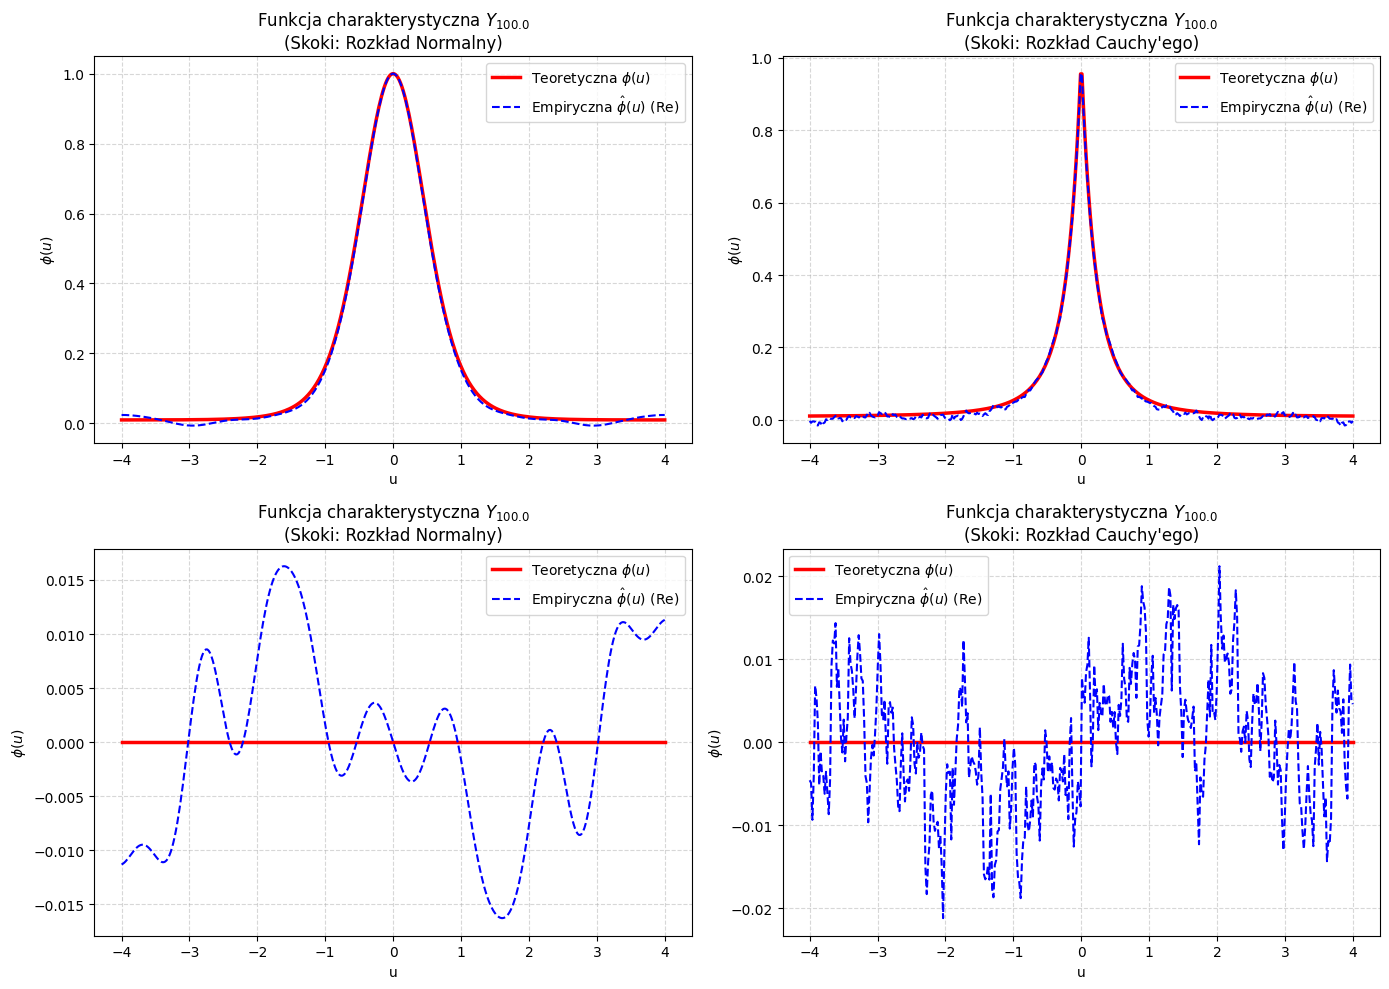

In [82]:
n_simulations = 5000  
T= 100.0        # Moment czasu, dla którego badamy rozkład punktowy Y_t
M= 1.0         # maximum of lambda(t)
u_vals = np.linspace(-4, 4, 400)

lambda_integral, _ = scipy.integrate.quad(example_func,0,T)

end_values_normal = []
end_values_cauchy = []

for _ in range(n_simulations):
    # Normal
    _, J_normal = NHPP_thining_normal(M, T, example_func)
    if len(J_normal) == 0:
        end_values_normal.append(0)
    else:
        end_values_normal.append(J_normal[-1])

    # Cauchy
    _, J_cauchy = NHPP_thining_cauchy(M,T,example_func)
    if len(J_cauchy) == 0:
        end_values_cauchy.append(0)
    else:
        end_values_cauchy.append(J_cauchy[-1])

end_values_normal = np.array(end_values_normal)
end_values_cauchy = np.array(end_values_cauchy)

ecf_normal = empirical_cf(u_vals, end_values_normal)
ecf_cauchy = empirical_cf(u_vals, end_values_cauchy)

# characteristics function for normal
phi_Z_normal = np.exp(-0.5 * u_vals**2)
tcf_normal = np.exp(lambda_integral * (phi_Z_normal - 1))

# characteristisc function for cauchy: phi_Z(u) = exp(-|u|)
phi_Z_cauchy = np.exp(-np.abs(u_vals))
tcf_cauchy = np.exp(lambda_integral * (phi_Z_cauchy - 1))

# Visualization
plt.figure(figsize=(14, 10))

# Normal
plt.subplot(2, 2, 1)
plt.plot(u_vals, tcf_normal, 'r-', linewidth=2.5, label='Teoretyczna $\\phi(u)$')
plt.plot(u_vals, np.real(ecf_normal), 'b--', label='Empiryczna $\\hat{\\phi}(u)$ (Re)')
plt.title(f"Funkcja charakterystyczna $Y_{{{T}}}$\n(Skoki: Rozkład Normalny)")
plt.xlabel("u")
plt.ylabel("$\\phi(u)$")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(2, 2, 3)
plt.plot([min(u_vals), max(u_vals)], [0,0], 'r-', linewidth=2.5, label='Teoretyczna $\\phi(u)$')
plt.plot(u_vals, np.imag(ecf_normal), 'b--', label='Empiryczna $\\hat{\\phi}(u)$ (Re)')
plt.title(f"Funkcja charakterystyczna $Y_{{{T}}}$\n(Skoki: Rozkład Normalny)")
plt.xlabel("u")
plt.ylabel("$\\phi(u)$")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Cauchy
plt.subplot(2, 2, 2)
plt.plot(u_vals, tcf_cauchy, 'r-', linewidth=2.5, label='Teoretyczna $\\phi(u)$')
plt.plot(u_vals, np.real(ecf_cauchy), 'b--', label='Empiryczna $\\hat{\\phi}(u)$ (Re)')
plt.title(f"Funkcja charakterystyczna $Y_{{{T}}}$\n(Skoki: Rozkład Cauchy'ego)")
plt.xlabel("u")
plt.ylabel("$\\phi(u)$")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.subplot(2, 2, 4)
plt.plot([min(u_vals), max(u_vals)], [0,0], 'r-', linewidth=2.5, label='Teoretyczna $\\phi(u)$')
plt.plot(u_vals, np.imag(ecf_cauchy), 'b--', label='Empiryczna $\\hat{\\phi}(u)$ (Re)')
plt.title(f"Funkcja charakterystyczna $Y_{{{T}}}$\n(Skoki: Rozkład Cauchy'ego)")
plt.xlabel("u")
plt.ylabel("$\\phi(u)$")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
    

## Zadanie 7. Prosty proces ryzyka 

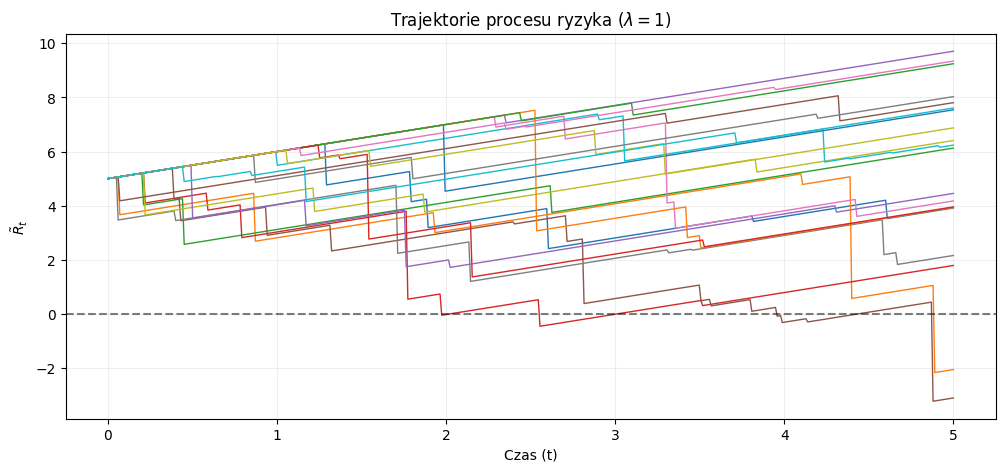

In [83]:
def get_value_risk_process(S,jumps,t,r0,c):
    """Returns value of  process ad given (t) time."""
    return r0+ c*t - jumps[get_poisson_value(S, t)-1]


def calculate_trajectories_risk_process(lamb_func, lamb, T, M, r0, c, num_paths=1):
    t_grid = np.linspace(0, T, int(T*100))
    all_trajectories = []
    for _ in range(num_paths):
        S, J = NHPP_thining_expon(M, T, lamb_func, lamb=lamb)
        if len(S) == 0:
            S = np.array([0])
            J = np.array([0])
        else:
            S = np.concatenate(([0], S, [S[-1]]))
            J = np.concatenate(([0], J, [J[-1]]))
        all_trajectories.append(get_value_risk_process(S, J, t_grid,r0,c))
    return np.array(all_trajectories)


def plot_trajectories(lamb_func, lamb, T, M, r0, c, num_paths=1):
    t_grid = np.linspace(0, T, int(T*100))

    plt.figure(figsize=(12,5))
    paths = calculate_trajectories_risk_process(lamb_func, lamb, T, M, r0, c, num_paths=num_paths)

    for path in paths:
        plt.plot(t_grid, path, linewidth=1)
    plt.axhline(0, color='black', linestyle='--', alpha=0.5)
    plt.title(f"Trajektorie procesu ryzyka ($\\lambda={lamb}$)")
    plt.xlabel("Czas (t)")
    plt.ylabel("$\\~{R}_t$")
    plt.grid(True, alpha=0.2)
    plt.show()


M=1 #Max of lambda(t)
T=5
r0=5
c=1
lamb=1
plot_trajectories(lambda x: 1,lamb, T, M, r0, c, num_paths=20)
#print(calculate_trajectories_risk_process(lambda x: 1,lamb, T, M, r0, c))

Wyznaczenie empirycznego prawdopodobieństwa niewypłacalności w momentach t=1,3,5

In [84]:
def probability_of_bankrupcy(lamb_func, lamb, T_list, M, r0, c, num_paths=100000):
    bankrupt_counts = {t: 0 for t in T_list}
    
    for _ in range(num_paths):
        # Generating trajectory for max T 
        max_T = max(T_list)
        S, J = NHPP_thining_expon(M, max_T, lamb_func, lamb=lamb)
        
        if len(S) > 0:
            # we can only become bankrupt at moments of jumps
            # calculate capital at jumps
            capital_at_jumps = r0 + c * S - J
            
            # check for each time period
            for t in T_list:
                # jumps to time t
                mask = S <= t
                jumps_before_t = capital_at_jumps[mask]
                
                # if in any of the moments capital < 0 -> bankrupt
                if len(jumps_before_t) > 0 and (jumps_before_t < 0).any():
                    bankrupt_counts[t] += 1
                    
    return {t: count / num_paths for t, count in bankrupt_counts.items()}

M = 1 # max of lambda(t)- intensity of the  func
T_moments = [1, 3, 5]
r0 = 5
c = 0.5
lamb = 1


wyniki = probability_of_bankrupcy(example_func, lamb, T_moments, M, r0, c, num_paths=10000)
print("Empiryczne prawdopodobieństwo niewypłacalności:", wyniki)

Empiryczne prawdopodobieństwo niewypłacalności: {1: 0.0088, 3: 0.0229, 5: 0.0283}


In [85]:
M = 1 # max of lambda(t)- intensity of the  func
T_moments = [1, 5, 100]
r0 = 5
c = 0.5
lamb = 1
wyniki = probability_of_bankrupcy(lambda x: 1.02+np.sin(x), lamb, T_moments, M, r0, c, num_paths=1000)
print("Empiryczne prawdopodobieństwo niewypłacalności:", wyniki)

Empiryczne prawdopodobieństwo niewypłacalności: {1: 0.021, 5: 0.153, 100: 0.956}
